# 08. Generalization Analysis — Phase A

baseline (v1, e15) vs v2 (e14) 모델 내부 메커니즘 진단.

## 목표
RTMDet-tiny 일반화 최고 성능 도달을 위한 모델 차원 진단. 데이터 처방(처방 1+2+3)이 학습 동역학을 어떻게 바꿨는지 측정으로 확정하고, 다음 사이클에서 건드릴 학습 사양(증강·하이퍼파라미터) 우선순위 도출.

## 항목 (Phase A 5개)
- **A-1. 학습 곡선** — cls/bbox loss epoch별, mAP 추이, plateau/overfit 시점, EMA 작동 여부
- **A-2. K-code val 2090장 클래스별 정답률** — Top-1/Top-3 매트릭스, 학습 데이터 양 vs 정답률 상관
- **A-3. Confusion 매트릭스 전수** — 시각적 유사 쌍 발굴, 합성 처방 vs 클래스 정의 차원 분리
- **A-4. 각인 학습 여부 직접 검증** — grad-CAM/feature attention, "형태/색만 보고 각인 안 본다" 가설 증명/기각
- **A-5. Head 단위 분리 측정** — cls head vs reg head 책임 분리, IoU 0.832가 진짜인지

## 데이터
- baseline work_dir: `D:\wony98_work_dir\` (RUN_TAG 없음, e15)
- v2 work_dir: `D:\wony98_v6_work_dir\` (RUN_TAG=v6 = 외부 v2, e14)

## 비교 기준
처방 1 (imgsz 640→1280), 처방 2 (n_pills별 lognormal), 처방 3 (개수 가중 1~4) 적용.
처방 4 미적용. 다음 사이클 사양 결정의 측정 근거.

In [1]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

BASELINE_WORK_DIR = Path(r'D:\wony98_work_dir')
V2_WORK_DIR       = Path(r'D:\wony98_v6_work_dir')


def find_scalars(work_dir: Path):
    """work_dir 하위에서 scalars.json + log.json 위치 자동 탐색."""
    if not work_dir.exists():
        return None, f'경로 없음: {work_dir}'
    scalars  = list(work_dir.rglob('scalars.json'))
    logjson  = list(work_dir.rglob('*.log.json'))
    return {'scalars': scalars, 'log_json': logjson}, None


for label, wd in [('Baseline (v1, e15)', BASELINE_WORK_DIR),
                  ('v2 (e14)',           V2_WORK_DIR)]:
    print(f'=== {label} ===')
    print(f'  work_dir: {wd}')
    print(f'  존재: {wd.exists()}')
    result, err = find_scalars(wd)
    if err:
        print(f'  [에러] {err}')
    else:
        print(f'  scalars.json: {len(result["scalars"])}건')
        for p in result['scalars']:
            size_kb = p.stat().st_size / 1024
            print(f'    - {p}  ({size_kb:.1f} KB)')
        print(f'  *.log.json: {len(result["log_json"])}건')
        for p in result['log_json']:
            size_kb = p.stat().st_size / 1024
            print(f'    - {p}  ({size_kb:.1f} KB)')
    print()

=== Baseline (v1, e15) ===
  work_dir: D:\wony98_work_dir
  존재: True
  scalars.json: 1건
    - D:\wony98_work_dir\20260501_074043\vis_data\scalars.json  (80.3 KB)
  *.log.json: 0건

=== v2 (e14) ===
  work_dir: D:\wony98_v6_work_dir
  존재: True
  scalars.json: 1건
    - D:\wony98_v6_work_dir\20260503_151609\vis_data\scalars.json  (80.2 KB)
  *.log.json: 0건



## 셀 2. scalars.json 자료구조 점검

파싱 전 키 분포 먼저 확인. mmengine 버전 차이로 키 이름이 다를 수 있어 자료구조 진단 후 본 파싱으로 진행.

In [2]:
import json
from pathlib import Path
from collections import Counter

BASELINE_SCALARS = Path(r'D:\wony98_work_dir\20260501_074043\vis_data\scalars.json')
V2_SCALARS       = Path(r'D:\wony98_v6_work_dir\20260503_151609\vis_data\scalars.json')


def load_scalars_jsonl(path: Path):
    """scalars.json은 JSONL 형식 (한 줄 한 dict). 라인별 파싱."""
    records = []
    with path.open('r', encoding='utf-8') as f:
        for i, line in enumerate(f):
            line = line.strip()
            if not line:
                continue
            try:
                records.append(json.loads(line))
            except json.JSONDecodeError as e:
                print(f'  [경고] line {i} 파싱 실패: {e}')
    return records


for label, p in [('Baseline', BASELINE_SCALARS), ('v2', V2_SCALARS)]:
    print(f'=== {label} ===')
    print(f'  path: {p}')
    records = load_scalars_jsonl(p)
    print(f'  레코드 수: {len(records)}')

    if records:
        # 첫 3개 레코드 키 확인
        print(f'  첫 레코드 키: {list(records[0].keys())}')
        print(f'  첫 레코드 샘플:')
        for k, v in list(records[0].items())[:8]:
            print(f'    {k}: {v}')

        # 전체 레코드의 키 분포 (어떤 키가 자주 등장하는지)
        all_keys = []
        for r in records:
            all_keys.extend(r.keys())
        key_counts = Counter(all_keys)
        print(f'  전체 키 분포 (등장 횟수):')
        for k, cnt in key_counts.most_common():
            print(f'    {k}: {cnt}')
    print()

=== Baseline ===
  path: D:\wony98_work_dir\20260501_074043\vis_data\scalars.json
  레코드 수: 299
  첫 레코드 키: ['base_lr', 'lr', 'data_time', 'loss', 'loss_cls', 'loss_bbox', 'time', 'epoch', 'iter', 'memory', 'step']
  첫 레코드 샘플:
    base_lr: 1.2264639639639638e-05
    lr: 1.2264639639639638e-05
    data_time: 0.025862298011779784
    loss: 2.768244156837463
    loss_cls: 2.1002548861503603
    loss_bbox: 0.6679892671108246
    time: 0.30038325309753416
    epoch: 1
  전체 키 분포 (등장 횟수):
    data_time: 299
    time: 299
    step: 299
    base_lr: 285
    lr: 285
    loss: 285
    loss_cls: 285
    loss_bbox: 285
    epoch: 285
    iter: 285
    memory: 285
    coco/bbox_mAP: 14
    coco/bbox_mAP_50: 14
    coco/bbox_mAP_75: 14
    coco/bbox_mAP_s: 14
    coco/bbox_mAP_m: 14
    coco/bbox_mAP_l: 14

=== v2 ===
  path: D:\wony98_v6_work_dir\20260503_151609\vis_data\scalars.json
  레코드 수: 299
  첫 레코드 키: ['base_lr', 'lr', 'data_time', 'loss', 'loss_cls', 'loss_bbox', 'time', 'epoch', 'iter', 'memor

## 셀 3. DataFrame 변환 + train/val 분리

285개 train 레코드(`loss_cls` 보유)와 14개 val 레코드(`coco/bbox_mAP_50` 보유)로 분리. epoch별 iter 수 + epoch별 평균 loss로 자료구조 검증.

In [4]:
import pandas as pd

def load_scalars_jsonl(path):
    records = []
    with path.open('r', encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            records.append(json.loads(line))
    return records


def split_train_val(records):
    """레코드를 train(loss_cls 있음)/val(coco/bbox_mAP_50 있음)로 분리."""
    train, val = [], []
    for r in records:
        if 'loss_cls' in r:
            train.append(r)
        elif 'coco/bbox_mAP_50' in r:
            val.append(r)
        else:
            # data_time/time만 있는 레코드 (학습 외 메타). 무시.
            pass
    return pd.DataFrame(train), pd.DataFrame(val)


# 두 모델 로드
runs = {}
for label, path in [('baseline', BASELINE_SCALARS), ('v2', V2_SCALARS)]:
    records = load_scalars_jsonl(path)
    train_df, val_df = split_train_val(records)
    runs[label] = {'train': train_df, 'val': val_df}
    print(f'=== {label} ===')
    print(f'  Train: {len(train_df)} rows, epoch {train_df["epoch"].min()}~{train_df["epoch"].max()}')
    print(f'    iter/epoch 분포: {train_df.groupby("epoch")["iter"].count().to_dict()}')
    print(f'  Val: {len(val_df)} rows')
    print(f'    val 컬럼: {[c for c in val_df.columns if "coco" in c or "step" in c]}')
    print()

# Sanity check: train epoch별 평균 loss 계산
print('=== Train epoch별 평균 loss (자료구조 검증) ===')
for label in ['baseline', 'v2']:
    df = runs[label]['train']
    epoch_loss = df.groupby('epoch')[['loss', 'loss_cls', 'loss_bbox']].mean().round(4)
    print(f'\n--- {label} ---')
    print(epoch_loss)

=== baseline ===
  Train: 285 rows, epoch 1~15
    iter/epoch 분포: {1: 19, 2: 19, 3: 19, 4: 19, 5: 19, 6: 19, 7: 19, 8: 19, 9: 19, 10: 19, 11: 19, 12: 19, 13: 19, 14: 19, 15: 19}
  Val: 14 rows
    val 컬럼: ['coco/bbox_mAP', 'coco/bbox_mAP_50', 'coco/bbox_mAP_75', 'coco/bbox_mAP_s', 'coco/bbox_mAP_m', 'coco/bbox_mAP_l', 'step']

=== v2 ===
  Train: 285 rows, epoch 1~15
    iter/epoch 분포: {1: 19, 2: 19, 3: 19, 4: 19, 5: 19, 6: 19, 7: 19, 8: 19, 9: 19, 10: 19, 11: 19, 12: 19, 13: 19, 14: 19, 15: 19}
  Val: 14 rows
    val 컬럼: ['coco/bbox_mAP', 'coco/bbox_mAP_50', 'coco/bbox_mAP_75', 'coco/bbox_mAP_s', 'coco/bbox_mAP_m', 'coco/bbox_mAP_l', 'step']

=== Train epoch별 평균 loss (자료구조 검증) ===

--- baseline ---
         loss  loss_cls  loss_bbox
epoch                             
1      1.8604    1.5563     0.3042
2      0.8318    0.6442     0.1876
3      0.6379    0.4638     0.1741
4      0.5574    0.3901     0.1673
5      0.5031    0.3427     0.1604
6      0.4762    0.3184     0.1578
7      0.45

## 셀 4. 학습 곡선 4-panel 시각화

baseline vs v2 epoch별 비교:
- Train total loss / cls loss / bbox loss
- Val mAP@50 (K-code val 2090장)
- epoch 10→11 변곡점 강조

목적: train 수렴 vs val 일반화 갭, augmentation 전환 효과, val mAP plateau 시점 시각 확인.

baseline val epoch: [0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1]
v2 val epoch: [0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1]


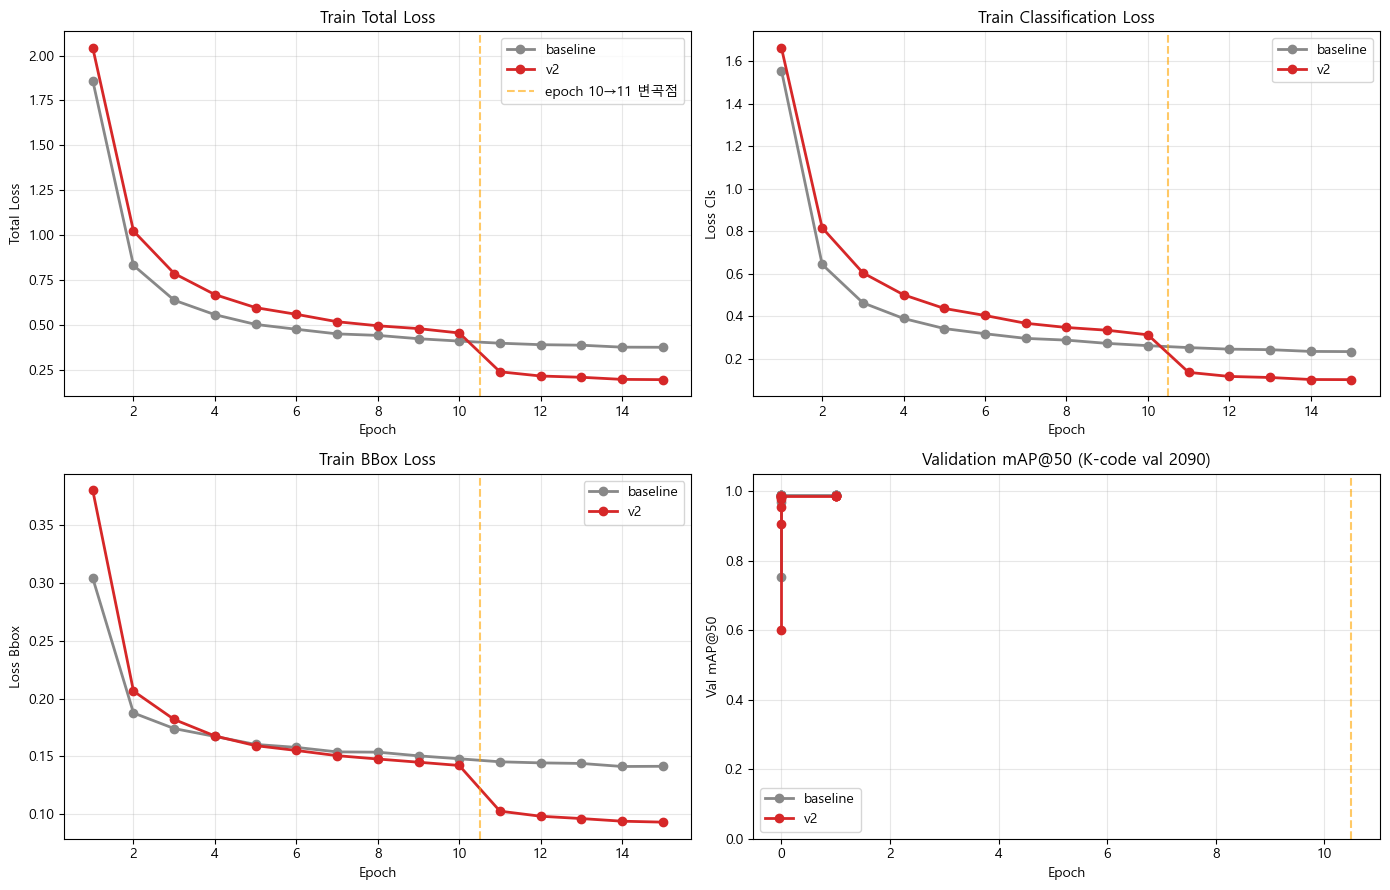


저장: D:\pill_detection\analysis\figures_generalization\08_training_curves.png

=== Epoch 10→11 변곡점 정량 ===

--- baseline ---
  total: 0.4103 → 0.3986  (-2.9%)
  cls:   0.2623 → 0.2532  (-3.5%)
  bbox:  0.1480 → 0.1454  (-1.8%)

--- v2 ---
  total: 0.4555 → 0.2394  (-47.4%)
  cls:   0.3133 → 0.1367  (-56.4%)
  bbox:  0.1422 → 0.1027  (-27.8%)

=== Val mAP@50 변곡점 전후 ===
    final: 0.9900, best: 0.9900 (epoch 0)
    final: 0.9870, best: 0.9870 (epoch 1)


In [5]:
import numpy as np
import matplotlib.pyplot as plt

# figures 폴더 생성
FIG_DIR = Path(r'D:\pill_detection\analysis\figures_generalization')
FIG_DIR.mkdir(parents=True, exist_ok=True)

# val df에 epoch 추정 컬럼 추가
ITERS_PER_EPOCH = 19  # train 285 / 15 epoch
for label in ['baseline', 'v2']:
    runs[label]['val'] = runs[label]['val'].copy()
    runs[label]['val']['epoch'] = (runs[label]['val']['step'] / ITERS_PER_EPOCH).round().astype(int)

# val epoch 분포 sanity
for label in ['baseline', 'v2']:
    print(f'{label} val epoch: {sorted(runs[label]["val"]["epoch"].tolist())}')

colors = {'baseline': '#888888', 'v2': '#d62728'}
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# (0,0) total loss
ax = axes[0, 0]
for label in ['baseline', 'v2']:
    df = runs[label]['train'].groupby('epoch')['loss'].mean()
    ax.plot(df.index, df.values, marker='o', label=label, color=colors[label], linewidth=2)
ax.axvline(10.5, color='orange', linestyle='--', alpha=0.6, label='epoch 10→11 변곡점')
ax.set_xlabel('Epoch'); ax.set_ylabel('Total Loss')
ax.set_title('Train Total Loss'); ax.legend(); ax.grid(alpha=0.3)

# (0,1) cls loss
ax = axes[0, 1]
for label in ['baseline', 'v2']:
    df = runs[label]['train'].groupby('epoch')['loss_cls'].mean()
    ax.plot(df.index, df.values, marker='o', label=label, color=colors[label], linewidth=2)
ax.axvline(10.5, color='orange', linestyle='--', alpha=0.6)
ax.set_xlabel('Epoch'); ax.set_ylabel('Loss Cls')
ax.set_title('Train Classification Loss'); ax.legend(); ax.grid(alpha=0.3)

# (1,0) bbox loss
ax = axes[1, 0]
for label in ['baseline', 'v2']:
    df = runs[label]['train'].groupby('epoch')['loss_bbox'].mean()
    ax.plot(df.index, df.values, marker='o', label=label, color=colors[label], linewidth=2)
ax.axvline(10.5, color='orange', linestyle='--', alpha=0.6)
ax.set_xlabel('Epoch'); ax.set_ylabel('Loss Bbox')
ax.set_title('Train BBox Loss'); ax.legend(); ax.grid(alpha=0.3)

# (1,1) val mAP@50
ax = axes[1, 1]
for label in ['baseline', 'v2']:
    df = runs[label]['val'].sort_values('epoch')
    ax.plot(df['epoch'], df['coco/bbox_mAP_50'], marker='o', label=label,
            color=colors[label], linewidth=2)
ax.axvline(10.5, color='orange', linestyle='--', alpha=0.6)
ax.set_xlabel('Epoch'); ax.set_ylabel('Val mAP@50')
ax.set_title('Validation mAP@50 (K-code val 2090)'); ax.legend(); ax.grid(alpha=0.3)
ax.set_ylim(0.0, 1.05)

plt.tight_layout()
fig_path = FIG_DIR / '08_training_curves.png'
plt.savefig(fig_path, dpi=120, bbox_inches='tight')
plt.show()
print(f'\n저장: {fig_path}')

# epoch 10→11 변곡점 수치
print('\n=== Epoch 10→11 변곡점 정량 ===')
for label in ['baseline', 'v2']:
    df = runs[label]['train'].groupby('epoch')[['loss', 'loss_cls', 'loss_bbox']].mean()
    e10, e11 = df.loc[10], df.loc[11]
    print(f'\n--- {label} ---')
    print(f'  total: {e10["loss"]:.4f} → {e11["loss"]:.4f}  ({(e11["loss"]/e10["loss"]-1)*100:+.1f}%)')
    print(f'  cls:   {e10["loss_cls"]:.4f} → {e11["loss_cls"]:.4f}  ({(e11["loss_cls"]/e10["loss_cls"]-1)*100:+.1f}%)')
    print(f'  bbox:  {e10["loss_bbox"]:.4f} → {e11["loss_bbox"]:.4f}  ({(e11["loss_bbox"]/e10["loss_bbox"]-1)*100:+.1f}%)')

# val mAP 변곡 전후
print('\n=== Val mAP@50 변곡점 전후 ===')
for label in ['baseline', 'v2']:
    df = runs[label]['val'].sort_values('epoch').set_index('epoch')
    if 10 in df.index and 11 in df.index:
        m10, m11 = df.loc[10, 'coco/bbox_mAP_50'], df.loc[11, 'coco/bbox_mAP_50']
        print(f'  {label}: epoch10 {m10:.4f} → epoch11 {m11:.4f}  ({(m11-m10)*100:+.2f}pp)')
    final = df['coco/bbox_mAP_50'].iloc[-1]
    best = df['coco/bbox_mAP_50'].max()
    best_epoch = df['coco/bbox_mAP_50'].idxmax()
    print(f'    final: {final:.4f}, best: {best:.4f} (epoch {best_epoch})')

## 셀 5. Val 자료구조 재진단

셀 4에서 val mAP epoch 매핑 실패 (epoch 0, 1만 나옴). val df의 step 컬럼 실제 값과 의미 직접 확인 후 매핑 재구성.

In [6]:
# val df 전체 컬럼 + 값 직접 출력
print('=== val df 직접 검토 ===\n')
for label in ['baseline', 'v2']:
    df = runs[label]['val'].copy()
    print(f'--- {label} ---')
    print(f'shape: {df.shape}')
    print(f'columns: {list(df.columns)}')
    print(f'\nstep 컬럼 unique 값들 (정렬):')
    print(sorted(df['step'].tolist()))
    print(f'\n전체 표 (mAP_50 기준 정렬):')
    show_cols = ['step', 'coco/bbox_mAP_50', 'coco/bbox_mAP', 'coco/bbox_mAP_75']
    print(df[show_cols].sort_values('step').to_string(index=False))
    print()

# 추가: train df의 epoch별 마지막 iter (val 시점이 train의 어디에 해당하는지 단서)
print('=== train df epoch별 마지막 iter (참고) ===')
for label in ['baseline', 'v2']:
    df = runs[label]['train']
    last_iter = df.groupby('epoch')['iter'].max()
    print(f'\n{label}:')
    print(last_iter.to_dict())

=== val df 직접 검토 ===

--- baseline ---
shape: (14, 10)
columns: ['coco/bbox_mAP', 'coco/bbox_mAP_50', 'coco/bbox_mAP_75', 'coco/bbox_mAP_s', 'coco/bbox_mAP_m', 'coco/bbox_mAP_l', 'data_time', 'time', 'step', 'epoch']

step 컬럼 unique 값들 (정렬):
[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]

전체 표 (mAP_50 기준 정렬):
 step  coco/bbox_mAP_50  coco/bbox_mAP  coco/bbox_mAP_75
    1             0.753          0.683             0.745
    2             0.968          0.895             0.961
    3             0.983          0.915             0.974
    4             0.988          0.926             0.982
    5             0.989          0.929             0.984
    6             0.990          0.931             0.982
    7             0.989          0.921             0.983
    8             0.990          0.941             0.984
    9             0.990          0.938             0.984
   10             0.990          0.942             0.985
   11             0.990          0.943             0.984
   1

## 셀 6. Val mAP 매핑 정정 + 학습 곡선 v2 (early stopping 시점 명시)

셀 4 val 패널 매핑 오류 정정. val df의 기존 epoch 컬럼 그대로 사용 (덮어쓰기 X).
plot에 best epoch 마커 추가 — val mAP 천장 도달 시점 명시.
mAP@50 + mAP@75 두 곡선 같이 → 천장 효과 시각 확인.

In [7]:
# val df epoch 컬럼 직접 사용 (덮어쓰기 안 함)
# step 컬럼이 1~14인 게 val 차수, epoch 컬럼이 실제 epoch
# 출력에서 epoch 컬럼 값 확인 안 됐으니 일단 직접 점검부터

print('=== val df의 epoch 컬럼 실제 값 ===\n')
for label in ['baseline', 'v2']:
    df = runs[label]['val']
    print(f'--- {label} ---')
    print(df[['step', 'epoch', 'coco/bbox_mAP_50', 'coco/bbox_mAP_75']].to_string(index=False))
    print()

=== val df의 epoch 컬럼 실제 값 ===

--- baseline ---
 step  epoch  coco/bbox_mAP_50  coco/bbox_mAP_75
    1      0             0.753             0.745
    2      0             0.968             0.961
    3      0             0.983             0.974
    4      0             0.988             0.982
    5      0             0.989             0.984
    6      0             0.990             0.982
    7      0             0.989             0.983
    8      0             0.990             0.984
    9      0             0.990             0.984
   10      1             0.990             0.985
   11      1             0.990             0.984
   12      1             0.990             0.984
   13      1             0.990             0.984
   14      1             0.990             0.983

--- v2 ---
 step  epoch  coco/bbox_mAP_50  coco/bbox_mAP_75
    1      0             0.600             0.597
    2      0             0.907             0.903
    3      0             0.954             0.951
    4    

## 셀 7. 학습 곡선 v2 (val 매핑 정정 + best epoch 명시)

val df의 step 컬럼을 epoch로 사용 (val_interval=1, mmengine 내부 epoch 컬럼 무시).
mAP@50 + mAP@75 두 곡선으로 천장 효과 시각화. best epoch 마커 추가.
다음 사이클의 적정 epoch 수 결정 근거.

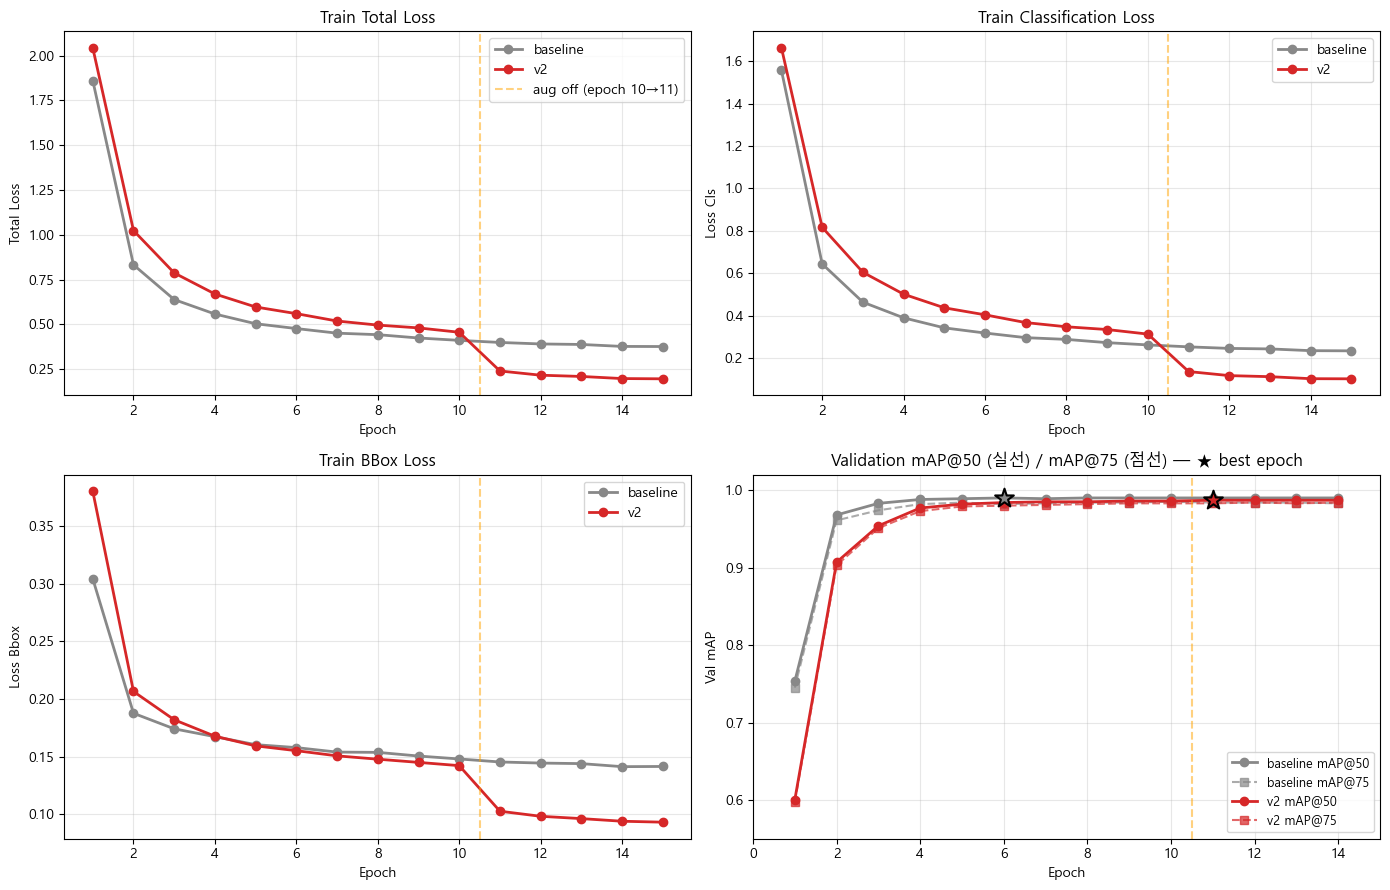


저장: D:\pill_detection\analysis\figures_generalization\08_training_curves_v2.png

=== 학습 곡선 정량 요약 ===

--- baseline ---
  val mAP@50: best 0.9900 (epoch 6), final epoch14 0.9900
  val mAP@75: best 0.9850
  천장 도달 (best의 99%): epoch 3
  epoch 1 → epoch 3 차이: 23.0pp
  train cls loss: epoch1 1.5563 → epoch3 0.4638 → epoch15 0.2344
  천장 → 끝 사이: train cls loss -0.2294, val mAP@50 +0.70pp (overfit 시그널)

--- v2 ---
  val mAP@50: best 0.9870 (epoch 11), final epoch14 0.9870
  val mAP@75: best 0.9840
  천장 도달 (best의 99%): epoch 5
  epoch 1 → epoch 5 차이: 38.2pp
  train cls loss: epoch1 1.6627 → epoch5 0.4373 → epoch15 0.1025
  천장 → 끝 사이: train cls loss -0.3348, val mAP@50 +0.50pp (overfit 시그널)



In [8]:
import matplotlib.pyplot as plt

# val 매핑: step = epoch (val_interval=1)
for label in ['baseline', 'v2']:
    runs[label]['val'] = runs[label]['val'].copy()
    runs[label]['val']['epoch_real'] = runs[label]['val']['step']

colors = {'baseline': '#888888', 'v2': '#d62728'}
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# (0,0) total loss
ax = axes[0, 0]
for label in ['baseline', 'v2']:
    df = runs[label]['train'].groupby('epoch')['loss'].mean()
    ax.plot(df.index, df.values, marker='o', label=label, color=colors[label], linewidth=2)
ax.axvline(10.5, color='orange', linestyle='--', alpha=0.5, label='aug off (epoch 10→11)')
ax.set_xlabel('Epoch'); ax.set_ylabel('Total Loss')
ax.set_title('Train Total Loss'); ax.legend(); ax.grid(alpha=0.3)

# (0,1) cls loss
ax = axes[0, 1]
for label in ['baseline', 'v2']:
    df = runs[label]['train'].groupby('epoch')['loss_cls'].mean()
    ax.plot(df.index, df.values, marker='o', label=label, color=colors[label], linewidth=2)
ax.axvline(10.5, color='orange', linestyle='--', alpha=0.5)
ax.set_xlabel('Epoch'); ax.set_ylabel('Loss Cls')
ax.set_title('Train Classification Loss'); ax.legend(); ax.grid(alpha=0.3)

# (1,0) bbox loss
ax = axes[1, 0]
for label in ['baseline', 'v2']:
    df = runs[label]['train'].groupby('epoch')['loss_bbox'].mean()
    ax.plot(df.index, df.values, marker='o', label=label, color=colors[label], linewidth=2)
ax.axvline(10.5, color='orange', linestyle='--', alpha=0.5)
ax.set_xlabel('Epoch'); ax.set_ylabel('Loss Bbox')
ax.set_title('Train BBox Loss'); ax.legend(); ax.grid(alpha=0.3)

# (1,1) val mAP — 50과 75 같이
ax = axes[1, 1]
for label in ['baseline', 'v2']:
    df = runs[label]['val'].sort_values('epoch_real')
    ax.plot(df['epoch_real'], df['coco/bbox_mAP_50'], marker='o',
            label=f'{label} mAP@50', color=colors[label], linewidth=2)
    ax.plot(df['epoch_real'], df['coco/bbox_mAP_75'], marker='s',
            label=f'{label} mAP@75', color=colors[label], linewidth=1.5,
            linestyle='--', alpha=0.7)
    # best epoch 마커
    best_idx = df['coco/bbox_mAP_50'].idxmax()
    best_epoch = df.loc[best_idx, 'epoch_real']
    best_map = df.loc[best_idx, 'coco/bbox_mAP_50']
    ax.scatter([best_epoch], [best_map], s=200, marker='*',
               color=colors[label], edgecolor='black', linewidth=1.5, zorder=5)
ax.axvline(10.5, color='orange', linestyle='--', alpha=0.5)
ax.set_xlabel('Epoch'); ax.set_ylabel('Val mAP')
ax.set_title('Validation mAP@50 (실선) / mAP@75 (점선) — ★ best epoch')
ax.legend(loc='lower right', fontsize=9); ax.grid(alpha=0.3)
ax.set_ylim(0.55, 1.02); ax.set_xlim(0, 15)

plt.tight_layout()
fig_path = FIG_DIR / '08_training_curves_v2.png'
plt.savefig(fig_path, dpi=120, bbox_inches='tight')
plt.show()
print(f'\n저장: {fig_path}')

# 정량 요약
print('\n=== 학습 곡선 정량 요약 ===\n')
for label in ['baseline', 'v2']:
    val_df = runs[label]['val'].sort_values('epoch_real').set_index('epoch_real')
    train_df = runs[label]['train'].groupby('epoch')[['loss', 'loss_cls']].mean()

    best_epoch = val_df['coco/bbox_mAP_50'].idxmax()
    best_map50 = val_df['coco/bbox_mAP_50'].max()
    final_map50 = val_df['coco/bbox_mAP_50'].iloc[-1]
    best_map75 = val_df['coco/bbox_mAP_75'].max()

    # 천장 도달 epoch (best 대비 99% 도달 시점)
    threshold = best_map50 * 0.99
    plateau_epoch = val_df[val_df['coco/bbox_mAP_50'] >= threshold].index.min()

    print(f'--- {label} ---')
    print(f'  val mAP@50: best {best_map50:.4f} (epoch {best_epoch}), final epoch14 {final_map50:.4f}')
    print(f'  val mAP@75: best {best_map75:.4f}')
    print(f'  천장 도달 (best의 99%): epoch {plateau_epoch}')
    print(f'  epoch 1 → epoch {plateau_epoch} 차이: {(val_df.loc[plateau_epoch, "coco/bbox_mAP_50"] - val_df.loc[1, "coco/bbox_mAP_50"]) * 100:.1f}pp')
    print(f'  train cls loss: epoch1 {train_df.loc[1, "loss_cls"]:.4f} → epoch{plateau_epoch} {train_df.loc[plateau_epoch, "loss_cls"]:.4f} → epoch15 {train_df.loc[15, "loss_cls"]:.4f}')
    over_train_loss = train_df.loc[15, 'loss_cls'] - train_df.loc[plateau_epoch, 'loss_cls']
    over_val_map = val_df.loc[14, 'coco/bbox_mAP_50'] - val_df.loc[plateau_epoch, 'coco/bbox_mAP_50']
    print(f'  천장 → 끝 사이: train cls loss {over_train_loss:+.4f}, val mAP@50 {over_val_map*100:+.2f}pp (overfit 시그널)')
    print()

## 셀 8. Best 체크포인트 위치 확인

A-2/A-3 추론에 사용할 best 체크포인트가 두 work_dir 안에 보존되어 있는지 확인.
mmengine 기본 동작: `save_best='auto'` 시 `best_*.pth` 형태로 따로 저장.
파일명에 epoch 번호 포함 (예: `best_coco_bbox_mAP_50_epoch_6.pth`).

체크 항목:
- `*.pth` 전체 명단 + 파일 크기
- best 체크포인트 epoch 번호 (학습 곡선 best와 일치 여부)
- last 체크포인트 (epoch 15) 별도 보존 여부

In [9]:
# work_dir 하위 .pth 파일 전수 검색
print('=== Baseline (v1, e15) work_dir 체크포인트 ===\n')
baseline_pths = sorted(BASELINE_WORK_DIR.rglob('*.pth'))
for p in baseline_pths:
    size_mb = p.stat().st_size / (1024 * 1024)
    rel = p.relative_to(BASELINE_WORK_DIR)
    print(f'  {rel}  ({size_mb:.1f} MB)')
print(f'  총 {len(baseline_pths)}개')

print('\n=== v2 (e14) work_dir 체크포인트 ===\n')
v2_pths = sorted(V2_WORK_DIR.rglob('*.pth'))
for p in v2_pths:
    size_mb = p.stat().st_size / (1024 * 1024)
    rel = p.relative_to(V2_WORK_DIR)
    print(f'  {rel}  ({size_mb:.1f} MB)')
print(f'  총 {len(v2_pths)}개')

# 학습 곡선 best epoch와 매칭 검증용 정보
print('\n=== 학습 곡선 best epoch 재인용 ===')
print('  baseline best: epoch 6 (val mAP@50 0.9900)')
print('  v2 best: epoch 11 (val mAP@50 0.9870)')
print('\nbest_*.pth 파일명에 위 epoch 번호가 포함되어 있어야 매칭 OK.')

=== Baseline (v1, e15) work_dir 체크포인트 ===

  best_coco_bbox_mAP_epoch_13.pth  (23.2 MB)
  epoch_12.pth  (60.7 MB)
  epoch_13.pth  (60.9 MB)
  epoch_14.pth  (61.0 MB)
  총 4개

=== v2 (e14) work_dir 체크포인트 ===

  best_coco_bbox_mAP_epoch_14.pth  (23.3 MB)
  epoch_12.pth  (60.8 MB)
  epoch_13.pth  (60.9 MB)
  epoch_14.pth  (61.0 MB)
  총 4개

=== 학습 곡선 best epoch 재인용 ===
  baseline best: epoch 6 (val mAP@50 0.9900)
  v2 best: epoch 11 (val mAP@50 0.9870)

best_*.pth 파일명에 위 epoch 번호가 포함되어 있어야 매칭 OK.


## 셀 9. mAP@50 vs mAP@50:95 학습 동역학 비교

저장된 best 체크포인트가 mAP@50:95 기준 (epoch 13/14)임을 발견.
mAP@50 (박스 위치 정확도 약함) vs mAP@50:95 (박스 정확도 strict)
별도 곡선으로 시각화 → classification 학습은 빨리 plateau,
localization 학습은 지속됨 가설 시각 검증.

A-5 (head 단위 책임 분리)의 첫 단서.

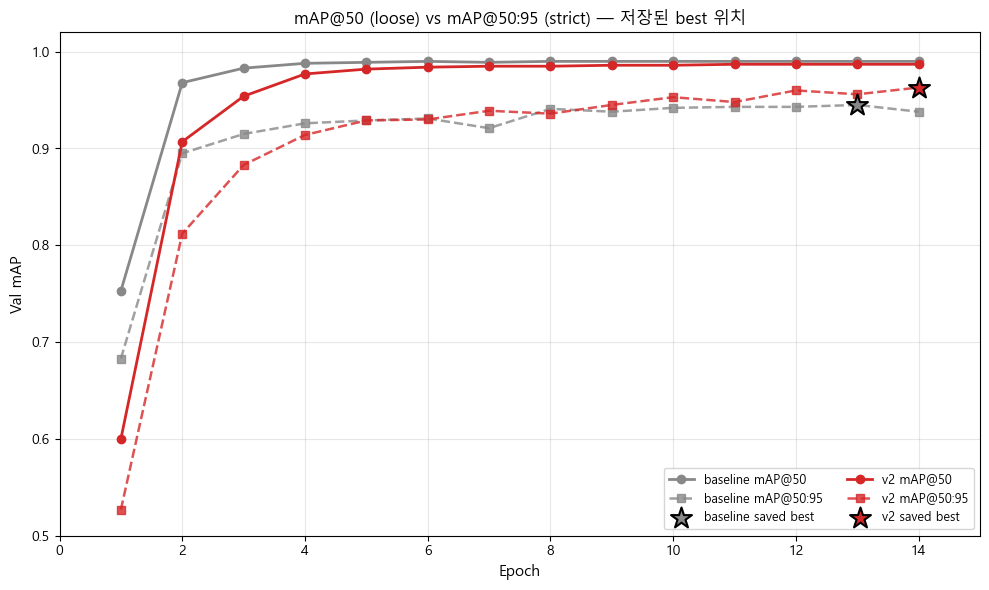


저장: D:\pill_detection\analysis\figures_generalization\08_map50_vs_map5095.png

=== mAP@50 vs mAP@50:95 plateau 시점 비교 ===

  [baseline - mAP@50]
    best: 0.9900 (epoch 6)
    99% plateau: epoch 3  (epoch1 → epoch3: +23.0pp)
  [baseline - mAP@50:95]
    best: 0.9450 (epoch 13)
    99% plateau: epoch 8  (epoch1 → epoch8: +25.8pp)
  [v2 - mAP@50]
    best: 0.9870 (epoch 11)
    99% plateau: epoch 5  (epoch1 → epoch5: +38.2pp)
  [v2 - mAP@50:95]
    best: 0.9630 (epoch 14)
    99% plateau: epoch 12  (epoch1 → epoch12: +43.3pp)

=== 핵심: classification vs localization 학습 동역학 ===
  baseline: mAP@50 plateau epoch 3, mAP@50:95 plateau epoch 8 (차이 5 epoch)
  v2: mAP@50 plateau epoch 5, mAP@50:95 plateau epoch 12 (차이 7 epoch)


In [10]:
fig, ax = plt.subplots(1, 1, figsize=(10, 6))

for label in ['baseline', 'v2']:
    df = runs[label]['val'].sort_values('epoch_real')
    # mAP@50 (loose)
    ax.plot(df['epoch_real'], df['coco/bbox_mAP_50'], marker='o',
            label=f'{label} mAP@50', color=colors[label], linewidth=2)
    # mAP@50:95 (strict, == coco/bbox_mAP)
    ax.plot(df['epoch_real'], df['coco/bbox_mAP'], marker='s',
            label=f'{label} mAP@50:95', color=colors[label],
            linewidth=1.8, linestyle='--', alpha=0.8)

    # best epoch 마커 (mAP@50:95 기준 = 저장된 best)
    best_idx = df['coco/bbox_mAP'].idxmax()
    best_epoch = df.loc[best_idx, 'epoch_real']
    best_map = df.loc[best_idx, 'coco/bbox_mAP']
    ax.scatter([best_epoch], [best_map], s=250, marker='*',
               color=colors[label], edgecolor='black', linewidth=1.5,
               zorder=5, label=f'{label} saved best')

ax.set_xlabel('Epoch', fontsize=11)
ax.set_ylabel('Val mAP', fontsize=11)
ax.set_title('mAP@50 (loose) vs mAP@50:95 (strict) — 저장된 best 위치')
ax.legend(loc='lower right', fontsize=9, ncol=2)
ax.grid(alpha=0.3)
ax.set_ylim(0.50, 1.02)
ax.set_xlim(0, 15)

plt.tight_layout()
fig_path = FIG_DIR / '08_map50_vs_map5095.png'
plt.savefig(fig_path, dpi=120, bbox_inches='tight')
plt.show()
print(f'\n저장: {fig_path}')

# 정량: mAP@50과 mAP@50:95 plateau 시점 분리
print('\n=== mAP@50 vs mAP@50:95 plateau 시점 비교 ===\n')
for label in ['baseline', 'v2']:
    df = runs[label]['val'].sort_values('epoch_real').set_index('epoch_real')

    for metric_key, metric_name in [('coco/bbox_mAP_50', 'mAP@50'),
                                     ('coco/bbox_mAP', 'mAP@50:95')]:
        best_val = df[metric_key].max()
        best_ep = df[metric_key].idxmax()
        # 천장 도달 (best의 99%)
        plateau_ep = df[df[metric_key] >= best_val * 0.99].index.min()
        # epoch 1 → plateau pp 변화
        gain = (df.loc[plateau_ep, metric_key] - df.loc[1, metric_key]) * 100

        print(f'  [{label} - {metric_name}]')
        print(f'    best: {best_val:.4f} (epoch {best_ep})')
        print(f'    99% plateau: epoch {plateau_ep}  (epoch1 → epoch{plateau_ep}: +{gain:.1f}pp)')

# 핵심 인사이트 정량
print('\n=== 핵심: classification vs localization 학습 동역학 ===')
for label in ['baseline', 'v2']:
    df = runs[label]['val'].sort_values('epoch_real').set_index('epoch_real')
    map50_plateau = df[df['coco/bbox_mAP_50'] >= df['coco/bbox_mAP_50'].max() * 0.99].index.min()
    map_plateau = df[df['coco/bbox_mAP'] >= df['coco/bbox_mAP'].max() * 0.99].index.min()
    print(f'  {label}: mAP@50 plateau epoch {map50_plateau}, mAP@50:95 plateau epoch {map_plateau} (차이 {map_plateau - map50_plateau} epoch)')

# Phase A-2/A-3. 클래스별 정답률 + Confusion 분석

K-code val 2090장 (Colab 추론 결과) 기반 클래스별 매트릭스.

## 데이터
- baseline 추론: `data/predictions_baseline_kcode_val_2090.json` (8,373 그룹)
- v2 추론:       `data/predictions_v2_kcode_val_2090.json` (21,707 그룹)
- GT (COCO):     `data/val_kcode_coco.json` (2,090 images, 8,020 annotations)

## 도메인 한정
K-code val은 모두 3~4개 알약 케이스 (1~2개 알약 0건). 33장 Test (1개 60.6%)와 도메인 다름.
A-2 분석은 "3~4개 알약 케이스에서의 클래스별 정답률"로 한정 해석.

## 셀 10. 자료구조 진단

3개 JSON 파일 로드 후 키 구조 직접 확인 (추측 금지).

In [11]:
import json
from pathlib import Path
from collections import Counter

DATA_DIR = Path(r'D:\pill_detection\analysis\data')

# 3개 파일 로드
with open(DATA_DIR / 'predictions_baseline_kcode_val_2090.json', encoding='utf-8') as f:
    pred_baseline = json.load(f)
with open(DATA_DIR / 'predictions_v2_kcode_val_2090.json', encoding='utf-8') as f:
    pred_v2 = json.load(f)
with open(DATA_DIR / 'val_kcode_coco.json', encoding='utf-8') as f:
    gt_coco = json.load(f)

# ───── 자료구조 진단 ─────
print('=== predictions_baseline 자료구조 ===')
print(f'  type: {type(pred_baseline).__name__}')
print(f'  키 개수: {len(pred_baseline)}')
first_key = list(pred_baseline.keys())[0]
print(f'  첫 키: {first_key}')
first_val = pred_baseline[first_key]
print(f'  첫 값 type: {type(first_val).__name__}, 길이: {len(first_val)}')
if first_val:
    print(f'  첫 값[0] 키: {list(first_val[0].keys())}')
    print(f'  첫 값[0]: {first_val[0]}')
print()

print('=== predictions_v2 자료구조 ===')
print(f'  type: {type(pred_v2).__name__}')
print(f'  키 개수: {len(pred_v2)}')
first_v2 = pred_v2[first_key] if first_key in pred_v2 else pred_v2[list(pred_v2.keys())[0]]
print(f'  같은 이미지 그룹 수: {len(first_v2)}')
print()

print('=== gt_coco 자료구조 ===')
print(f'  최상위 키: {list(gt_coco.keys())}')
print(f'  images: {len(gt_coco["images"])}')
print(f'  annotations: {len(gt_coco["annotations"])}')
print(f'  categories: {len(gt_coco["categories"])}')
print(f'  첫 image: {gt_coco["images"][0]}')
print(f'  첫 annotation: {gt_coco["annotations"][0]}')
print(f'  첫 category: {gt_coco["categories"][0]}')
print()

# ───── 이미지 키 일치 검증 ─────
print('=== 이미지 키 매칭 검증 ===')
gt_filenames = {img['file_name'] for img in gt_coco['images']}
baseline_keys = set(pred_baseline.keys())
v2_keys = set(pred_v2.keys())

print(f'  GT 이미지 수:   {len(gt_filenames)}')
print(f'  baseline 키 수: {len(baseline_keys)}')
print(f'  v2 키 수:       {len(v2_keys)}')
print(f'  GT ∩ baseline: {len(gt_filenames & baseline_keys)}')
print(f'  GT ∩ v2:       {len(gt_filenames & v2_keys)}')

assert gt_filenames == baseline_keys == v2_keys, '이미지 키 불일치'
print('\n✅ 모든 이미지 키 일치 (2090)')

# ───── annotation 분포 sanity ─────
ann_per_img = Counter()
for ann in gt_coco['annotations']:
    ann_per_img[ann['image_id']] += 1
n_dist = Counter(ann_per_img.values())
print(f'\n이미지당 annotation 수 분포: {dict(sorted(n_dist.items()))}')

=== predictions_baseline 자료구조 ===
  type: dict
  키 개수: 2090
  첫 키: K-000250-000573-002483-006192_0_2_0_2_70_000_200.png
  첫 값 type: list, 길이: 5
  첫 값[0] 키: ['bbox', 'top3_class_idx', 'top3_class_name', 'top3_confidence']
  첫 값[0]: {'bbox': [74.96189880371094, 189.85324096679688, 368.2387390136719, 485.59283447265625], 'top3_class_idx': [1, 40, 88], 'top3_class_name': ['게보린정 300mg/PTP', '크레스토정 20mg', '디카테오정'], 'top3_confidence': [0.9603840708732605, 0.08194588124752045, 0.059633519500494]}

=== predictions_v2 자료구조 ===
  type: dict
  키 개수: 2090
  같은 이미지 그룹 수: 10

=== gt_coco 자료구조 ===
  최상위 키: ['images', 'annotations', 'categories']
  images: 2090
  annotations: 8020
  categories: 118
  첫 image: {'id': 1, 'file_name': 'K-000250-000573-002483-006192_0_2_0_2_70_000_200.png', 'width': 976, 'height': 1280, 'abs_path': '/content/dataset_yolo/images/val/K-000250-000573-002483-006192_0_2_0_2_70_000_200.png'}
  첫 annotation: {'id': 1, 'image_id': 1, 'category_id': 1, 'bbox': [553.000136, 183.9993

## 셀 11. GT-pred 매칭 (IoU 0.5)

각 GT 박스에 대해 가장 IoU 높은 예측 그룹 매칭 (greedy).
verdict 분류:
- **top1**: 매칭 그룹의 1순위 클래스 = GT 클래스
- **top3**: 매칭 그룹의 Top-3 안에 GT 클래스 있음 (1순위는 아님)
- **det_only**: 박스 매칭은 됐지만 Top-3에 GT 클래스 없음
- **det_fail**: GT 박스에 매칭되는 예측 그룹 없음 (IoU<0.5)

진단 노트북 셀 5 + 분석 노트북 06 셀 4-5 패턴.
출력: df_baseline, df_v2 (각 8020 GT × verdict 컬럼).

In [12]:
import pandas as pd
import numpy as np


def iou_xyxy(b1, b2):
    """xyxy IoU."""
    x1, y1 = max(b1[0], b2[0]), max(b1[1], b2[1])
    x2, y2 = min(b1[2], b2[2]), min(b1[3], b2[3])
    inter = max(0, x2 - x1) * max(0, y2 - y1)
    a1 = (b1[2] - b1[0]) * (b1[3] - b1[1])
    a2 = (b2[2] - b2[0]) * (b2[3] - b2[1])
    return inter / (a1 + a2 - inter + 1e-9)


def xywh_to_xyxy(b):
    return [b[0], b[1], b[0] + b[2], b[1] + b[3]]


# image_id → file_name + GT annotations 매핑
img_id_to_fname = {img['id']: img['file_name'] for img in gt_coco['images']}
gt_per_img = {}
for ann in gt_coco['annotations']:
    fname = img_id_to_fname[ann['image_id']]
    if fname not in gt_per_img:
        gt_per_img[fname] = []
    gt_per_img[fname].append({
        'bbox_xyxy': xywh_to_xyxy(ann['bbox']),
        'cat_id': ann['category_id'],          # 1~118
        'cat_idx': ann['category_id'] - 1,     # 0~117 (학습 인덱스)
        'cat_name': gt_coco['categories'][ann['category_id'] - 1]['name'],
    })

print(f'GT 매핑 완료: {len(gt_per_img)} 이미지')

# 진단 셀 패턴 - GT 박스마다 IoU 가장 큰 예측 그룹 찾기
def match_gt_to_preds(gt_per_img, pred_per_img, iou_thr=0.5):
    """각 GT에 대해 verdict 결정. greedy 매칭 (IoU 가장 높은 그룹부터)."""
    rows = []
    for fname, gts in gt_per_img.items():
        preds = pred_per_img.get(fname, [])

        # 모든 (gt, pred) 쌍의 IoU 계산
        n_gt, n_pr = len(gts), len(preds)
        if n_pr == 0:
            for gt in gts:
                rows.append({
                    'file_name': fname,
                    'gt_cat_idx': gt['cat_idx'],
                    'gt_cat_name': gt['cat_name'],
                    'verdict': 'det_fail',
                    'matched_pred_idx': -1,
                    'top1_idx': -1, 'top1_name': '', 'top1_conf': 0.0,
                    'top3_idx': [], 'top3_name': [],
                })
            continue

        # IoU 행렬
        iou_matrix = np.zeros((n_gt, n_pr))
        for i, gt in enumerate(gts):
            for j, pr in enumerate(preds):
                iou_matrix[i, j] = iou_xyxy(gt['bbox_xyxy'], pr['bbox'])

        # greedy: 가장 IoU 큰 쌍부터 매칭
        gt_used = [False] * n_gt
        pr_used = [False] * n_pr
        gt_to_pr = [-1] * n_gt

        # IoU 큰 순으로 sort
        flat = [(iou_matrix[i, j], i, j) for i in range(n_gt) for j in range(n_pr)]
        flat.sort(key=lambda x: -x[0])
        for iou_val, i, j in flat:
            if iou_val < iou_thr:
                break
            if not gt_used[i] and not pr_used[j]:
                gt_used[i] = True
                pr_used[j] = True
                gt_to_pr[i] = j

        # verdict 결정
        for i, gt in enumerate(gts):
            if gt_to_pr[i] == -1:
                rows.append({
                    'file_name': fname,
                    'gt_cat_idx': gt['cat_idx'],
                    'gt_cat_name': gt['cat_name'],
                    'verdict': 'det_fail',
                    'matched_pred_idx': -1,
                    'top1_idx': -1, 'top1_name': '', 'top1_conf': 0.0,
                    'top3_idx': [], 'top3_name': [],
                })
            else:
                pr = preds[gt_to_pr[i]]
                top3_idx = pr['top3_class_idx']
                top1_idx = top3_idx[0]
                if top1_idx == gt['cat_idx']:
                    verdict = 'top1'
                elif gt['cat_idx'] in top3_idx:
                    verdict = 'top3'
                else:
                    verdict = 'det_only'
                rows.append({
                    'file_name': fname,
                    'gt_cat_idx': gt['cat_idx'],
                    'gt_cat_name': gt['cat_name'],
                    'verdict': verdict,
                    'matched_pred_idx': gt_to_pr[i],
                    'top1_idx': top1_idx,
                    'top1_name': pr['top3_class_name'][0],
                    'top1_conf': pr['top3_confidence'][0],
                    'top3_idx': top3_idx,
                    'top3_name': pr['top3_class_name'],
                })

    return pd.DataFrame(rows)


print('\n=== baseline 매칭 ===')
df_baseline = match_gt_to_preds(gt_per_img, pred_baseline, iou_thr=0.5)
print(f'  매칭 결과: {len(df_baseline)} GT')
print(f'  verdict 분포:\n{df_baseline["verdict"].value_counts()}')

print('\n=== v2 매칭 ===')
df_v2 = match_gt_to_preds(gt_per_img, pred_v2, iou_thr=0.5)
print(f'  매칭 결과: {len(df_v2)} GT')
print(f'  verdict 분포:\n{df_v2["verdict"].value_counts()}')

# 핵심 지표 비교
print('\n=== 핵심 지표 비교 ===')
for label, df in [('baseline', df_baseline), ('v2', df_v2)]:
    n = len(df)
    n_top1 = (df['verdict'] == 'top1').sum()
    n_top3 = (df['verdict'].isin(['top1', 'top3'])).sum()
    n_det = (df['verdict'] != 'det_fail').sum()
    print(f'  {label}: Top-1 {n_top1/n*100:5.1f}% ({n_top1}/{n}), '
          f'Top-3 {n_top3/n*100:5.1f}%, Detection {n_det/n*100:5.1f}%')

GT 매핑 완료: 2090 이미지

=== baseline 매칭 ===
  매칭 결과: 8020 GT
  verdict 분포:
verdict
top1        7956
det_fail      40
top3          17
det_only       7
Name: count, dtype: int64

=== v2 매칭 ===
  매칭 결과: 8020 GT
  verdict 분포:
verdict
top1        7815
top3         156
det_fail      41
det_only       8
Name: count, dtype: int64

=== 핵심 지표 비교 ===
  baseline: Top-1  99.2% (7956/8020), Top-3  99.4%, Detection  99.5%
  v2: Top-1  97.4% (7815/8020), Top-3  99.4%, Detection  99.5%


## 셀 12. Verdict 페어 매트릭스 + 클래스 명단 추출

baseline → v2 verdict 변화를 GT 단위로 매트릭스화 (4×4).
세 명단 추출:
- v2 후퇴: baseline top1 → v2 (top3/det_only/det_fail)
- 공통 실패: baseline (top3/det_only/det_fail) ∩ v2 (top3/det_only/det_fail) = 모델 capacity 한계 클래스
- v2 회복: baseline (top3/det_only/det_fail) → v2 top1

In [13]:
# 두 df를 (file_name, gt_cat_idx) 키로 join — 같은 GT가 양쪽에 있어야 함
df_paired = df_baseline.merge(
    df_v2[['file_name', 'gt_cat_idx', 'verdict', 'top1_idx', 'top1_name', 'top1_conf', 'top3_idx']],
    on=['file_name', 'gt_cat_idx'],
    suffixes=('_baseline', '_v2'),
    how='inner'
)

print(f'Paired GT: {len(df_paired)} (양쪽 df 8020 일치)')

# verdict 페어 매트릭스 (4×4)
print('\n=== Verdict 페어 매트릭스 (baseline → v2) ===')
verdict_order = ['top1', 'top3', 'det_only', 'det_fail']
pair_matrix = pd.crosstab(
    df_paired['verdict_baseline'],
    df_paired['verdict_v2'],
).reindex(index=verdict_order, columns=verdict_order, fill_value=0)
print(pair_matrix)
print(f'\n총합 행=baseline, 열=v2: 합계 {pair_matrix.values.sum()}')

# 회복/유지/후퇴 분포
verdict_rank = {'top1': 0, 'top3': 1, 'det_only': 2, 'det_fail': 3}
df_paired['rank_baseline'] = df_paired['verdict_baseline'].map(verdict_rank)
df_paired['rank_v2'] = df_paired['verdict_v2'].map(verdict_rank)
df_paired['change'] = np.sign(df_paired['rank_baseline'] - df_paired['rank_v2'])  # +1 회복, 0 유지, -1 후퇴

n_recovered = (df_paired['change'] > 0).sum()
n_kept = (df_paired['change'] == 0).sum()
n_regressed = (df_paired['change'] < 0).sum()
print(f'\n회복: {n_recovered}, 유지: {n_kept}, 후퇴: {n_regressed}')

# ───── 1. v2 후퇴 GT (baseline top1 → v2 top1 아님) ─────
df_regressed = df_paired[
    (df_paired['verdict_baseline'] == 'top1') &
    (df_paired['verdict_v2'] != 'top1')
].copy()
print(f'\n=== v2 후퇴: baseline top1 → v2 top1 아님 ({len(df_regressed)} GT) ===')

# 클래스별 후퇴 수 (Top 10)
regressed_classes = df_regressed['gt_cat_name'].value_counts().head(10)
print(f'\n후퇴 클래스 Top 10:')
for cls, cnt in regressed_classes.items():
    cls_total_in_val = (df_paired['gt_cat_name'] == cls).sum()
    print(f'  {cls:50s} {cnt:>3}/{cls_total_in_val} ({cnt/cls_total_in_val*100:.0f}%)')

# ───── 2. 공통 실패 (양쪽 다 top1 아님) — 모델 capacity 한계 ─────
df_common_fail = df_paired[
    (df_paired['verdict_baseline'] != 'top1') &
    (df_paired['verdict_v2'] != 'top1')
].copy()
print(f'\n=== 공통 실패: 양쪽 다 top1 아님 ({len(df_common_fail)} GT) ===')

common_fail_classes = df_common_fail['gt_cat_name'].value_counts().head(10)
print(f'\n공통 실패 클래스 Top 10:')
for cls, cnt in common_fail_classes.items():
    cls_total = (df_paired['gt_cat_name'] == cls).sum()
    print(f'  {cls:50s} {cnt:>3}/{cls_total} ({cnt/cls_total*100:.0f}%)')

# ───── 3. v2 회복 GT (baseline top1 아님 → v2 top1) ─────
df_recovered = df_paired[
    (df_paired['verdict_baseline'] != 'top1') &
    (df_paired['verdict_v2'] == 'top1')
].copy()
print(f'\n=== v2 회복: baseline top1 아님 → v2 top1 ({len(df_recovered)} GT) ===')

recovered_classes = df_recovered['gt_cat_name'].value_counts().head(10)
print(f'\n회복 클래스 Top 10:')
for cls, cnt in recovered_classes.items():
    cls_total = (df_paired['gt_cat_name'] == cls).sum()
    print(f'  {cls:50s} {cnt:>3}/{cls_total} ({cnt/cls_total*100:.0f}%)')

Paired GT: 8020 (양쪽 df 8020 일치)

=== Verdict 페어 매트릭스 (baseline → v2) ===
verdict_v2        top1  top3  det_only  det_fail
verdict_baseline                                
top1              7802   152         1         1
top3                13     4         0         0
det_only             0     0         7         0
det_fail             0     0         0        40

총합 행=baseline, 열=v2: 합계 8020

회복: 13, 유지: 7853, 후퇴: 154

=== v2 후퇴: baseline top1 → v2 top1 아님 (154 GT) ===

후퇴 클래스 Top 10:
  동아오팔몬정(리마프로스트알파-시클로덱스트린포접화합물)                       43/122 (35%)
  디카테오엘씨정 10mg/병                                      32/68 (47%)
  비유피-4정 20mg                                         28/51 (55%)
  자누비아정 50mg                                           9/61 (15%)
  엘스테인캡슐(에르도스테인)                                       5/61 (8%)
  삐콤씨에프정 618.6mg/병                                     5/98 (5%)
  로수젯정10/5밀리그램                                         4/112 (4%)
  리피토정 20mg                                    

## 셀 13. 상위 3개 후퇴 클래스 정밀 분석

후퇴 154개 중 67% 차지하는 3개 클래스 — 동아오팔몬정, 디카테오엘씨정, 비유피-4정.

분석 항목:
1. v2 top1 오답이 어떤 클래스로 향하는지 (confusion 분포)
2. 학습 데이터에서 각 클래스의 GT 박스 수 (clean_df)
3. 시각적 유사 후보 (drug_shape + 색 톤)

## 데이터
- clean_df: `D:\pill_detection\data\team_preprocessed\clean_df.csv` (39,864 annotations)

In [14]:
import pandas as pd
from collections import Counter

# clean_df 로드 (학습 데이터 GT 분포 확인용)
CLEAN_DF_PATH = Path(r'D:\pill_detection\data\team_preprocessed\clean_df.csv')
df_clean = pd.read_csv(CLEAN_DF_PATH, low_memory=False)
print(f'clean_df: {df_clean.shape}')
print(f'columns 일부: {[c for c in df_clean.columns if c in ["dl_name", "drug_shape", "color_class1", "color_class2"]]}')
print()

# 분석 대상 3개 클래스
TARGET_CLASSES = [
    '동아오팔몬정(리마프로스트알파-시클로덱스트린포접화합물)',
    '디카테오엘씨정 10mg/병',
    '비유피-4정 20mg',
]

# clean_df의 dl_name 컬럼 확인
print(f'clean_df dl_name unique: {df_clean["dl_name"].nunique()}')
matched_in_clean = [cls for cls in TARGET_CLASSES if cls in df_clean['dl_name'].values]
print(f'TARGET_CLASSES 중 clean_df 매칭: {len(matched_in_clean)}/3')

# NBSP 등 정규화 시도
import unicodedata
def nfc(s):
    return unicodedata.normalize('NFC', str(s)).rstrip(' \t\xa0\u3000')

df_clean['dl_name_nfc'] = df_clean['dl_name'].apply(nfc)
TARGET_CLASSES_NFC = [nfc(c) for c in TARGET_CLASSES]
matched_nfc = [cls for cls in TARGET_CLASSES_NFC if cls in df_clean['dl_name_nfc'].values]
print(f'NFC 정규화 후 매칭: {len(matched_nfc)}/3')

clean_df: (39864, 45)
columns 일부: ['dl_name', 'color_class1', 'color_class2', 'drug_shape']

clean_df dl_name unique: 118
TARGET_CLASSES 중 clean_df 매칭: 3/3
NFC 정규화 후 매칭: 3/3


## 셀 14. 상위 3개 후퇴 클래스 — Confusion + 학습 데이터 양 + 시각 유사

3개 클래스 각각:
- (1) v2 top1 오답이 어떤 클래스로 향하는지 (confusion 분포)
- (2) clean_df 학습 데이터 GT 박스 수
- (3) drug_shape + color 같은 후보 클래스 명단 (시각 유사 가설)

In [18]:
# 학습 데이터 GT 분포
class_counts_train = df_clean['dl_name_nfc'].value_counts()
print(f'clean_df 클래스별 GT 수: 평균 {class_counts_train.mean():.0f} / 중앙값 {class_counts_train.median():.0f}')
print(f'  최소 {class_counts_train.min()} ~ 최대 {class_counts_train.max()}')


def safe_mode(s):
    s_clean = s.dropna()
    if len(s_clean) == 0:
        return ''
    m = s_clean.mode()
    return m.iloc[0] if len(m) > 0 else ''


class_meta = df_clean.groupby('dl_name_nfc').agg({
    'drug_shape':   safe_mode,
    'color_class1': safe_mode,
    'color_class2': safe_mode,
}).to_dict('index')

print(f'\nclass_meta: {len(class_meta)} 클래스')


def find_visual_similar(target_cls, class_meta, max_results=10):
    target = class_meta.get(target_cls, {})
    if not target.get('drug_shape') or not target.get('color_class1'):
        return []
    candidates = []
    for cls, meta in class_meta.items():
        if cls == target_cls:
            continue
        if meta['drug_shape'] == target['drug_shape'] and meta['color_class1'] == target['color_class1']:
            candidates.append(cls)
    return candidates[:max_results]


# 본 분석
for cls_name in TARGET_CLASSES:
    cls_nfc = nfc(cls_name)
    print('\n' + '=' * 70)
    print(f'클래스: {cls_name}')
    print('=' * 70)

    # (1) v2 top1 오답 confusion (컬럼명 _v2 적용)
    cls_regressed = df_regressed[df_regressed['gt_cat_name'] == cls_name]
    print(f'\n[1] v2 후퇴 GT: {len(cls_regressed)}건')
    if len(cls_regressed) > 0:
        confusion = cls_regressed['top1_name_v2'].value_counts()
        print(f'    v2 top1 오답 분포:')
        for wrong_cls, cnt in confusion.head(5).items():
            print(f'      {wrong_cls:50s} {cnt:>3}건 ({cnt/len(cls_regressed)*100:.0f}%)')

    # (2) 학습 데이터 GT 박스 수
    train_count = class_counts_train.get(cls_nfc, 0)
    rank = (class_counts_train > train_count).sum() + 1
    print(f'\n[2] 학습 데이터 GT 박스: {train_count}개 (118종 중 {rank}위, 평균 {class_counts_train.mean():.0f})')

    # (3) drug_shape + color
    target_meta = class_meta.get(cls_nfc, {})
    print(f'\n[3] 시각 정보:')
    print(f'    drug_shape:   {target_meta.get("drug_shape", "?")}')
    print(f'    color_class1: {target_meta.get("color_class1", "?")}')
    print(f'    color_class2: {target_meta.get("color_class2", "?")}')

    similar = find_visual_similar(cls_nfc, class_meta, max_results=10)
    print(f'    같은 shape + color_class1 클래스 ({len(similar)}건):')
    for s in similar[:8]:
        print(f'      - {s}')

    # confusion 1순위가 시각 유사 후보에 있는지 검증
    if len(cls_regressed) > 0 and len(similar) > 0:
        top_wrong = cls_regressed['top1_name_v2'].value_counts().index[0]
        top_wrong_nfc = nfc(top_wrong)
        is_similar = top_wrong_nfc in similar
        print(f'\n    ★ confusion 1순위 "{top_wrong[:30]}" 시각 유사 후보 매칭? {is_similar}')


# 정리 표
print('\n\n' + '=' * 70)
print('=== 3개 후퇴 클래스 요약 ===')
print('=' * 70)
summary_rows = []
for cls_name in TARGET_CLASSES:
    cls_nfc = nfc(cls_name)
    cls_regressed = df_regressed[df_regressed['gt_cat_name'] == cls_name]
    cls_total = (df_paired['gt_cat_name'] == cls_name).sum()
    train_count = class_counts_train.get(cls_nfc, 0)
    meta = class_meta.get(cls_nfc, {})
    summary_rows.append({
        'class': cls_name[:25],
        'val_총GT': cls_total,
        'v2_후퇴': len(cls_regressed),
        '후퇴율': f'{len(cls_regressed)/cls_total*100:.0f}%',
        '학습_GT수': train_count,
        'drug_shape': meta.get('drug_shape', '?'),
        'color': meta.get('color_class1', '?'),
    })
print(pd.DataFrame(summary_rows).to_string(index=False))

clean_df 클래스별 GT 수: 평균 338 / 중앙값 352
  최소 45 ~ 최대 882

class_meta: 118 클래스

클래스: 동아오팔몬정(리마프로스트알파-시클로덱스트린포접화합물)

[1] v2 후퇴 GT: 43건
    v2 top1 오답 분포:
      리피토정 20mg                                           43건 (100%)

[2] 학습 데이터 GT 박스: 630개 (118종 중 6위, 평균 338)

[3] 시각 정보:
    drug_shape:   원형
    color_class1: 하양
    color_class2: 
    같은 shape + color_class1 클래스 (10건):
      - 리피로우정 20mg
      - 리피토정 20mg
      - 마그밀정(수산화마그네슘)
      - 무코스타정(레바미피드)(비매품)
      - 비유피-4정 20mg
      - 삼남건조수산화알루미늄겔정
      - 스토가정 10mg
      - 아스피린프로텍트정 100mg

    ★ confusion 1순위 "리피토정 20mg" 시각 유사 후보 매칭? True

클래스: 디카테오엘씨정 10mg/병

[1] v2 후퇴 GT: 32건
    v2 top1 오답 분포:
      디카테오정                                               32건 (100%)

[2] 학습 데이터 GT 박스: 434개 (118종 중 31위, 평균 338)

[3] 시각 정보:
    drug_shape:   장방형
    color_class1: 하양
    color_class2: 
    같은 shape + color_class1 클래스 (10건):
      - 뉴로메드정(옥시라세탐)
      - 디카테오정
      - 라시도필캡슐(비매품)
      - 락토엔큐캡슐(바실루스리케니포르미스균)
      - 람노스캡슐500mg/병
      - 리렉스펜정 3

## 셀 15. Phase A-2/A-3 통합 figure — 라벨 이동 + 시각 유사 + 학습 양

3개 후퇴 클래스 분석 결과를 한 장에 통합:
- (a) 후퇴율 vs 학습 데이터 양 — 학습 양과 후퇴 무관 시각 검증
- (b) v2 후퇴 confusion 분포 — 라벨 이동 100% 수렴 시각화
- (c) verdict 페어 매트릭스 (4×4 히트맵)
- (d) 도메인 비교 — 33장 (HANDOFF44 박제값) vs val 2090

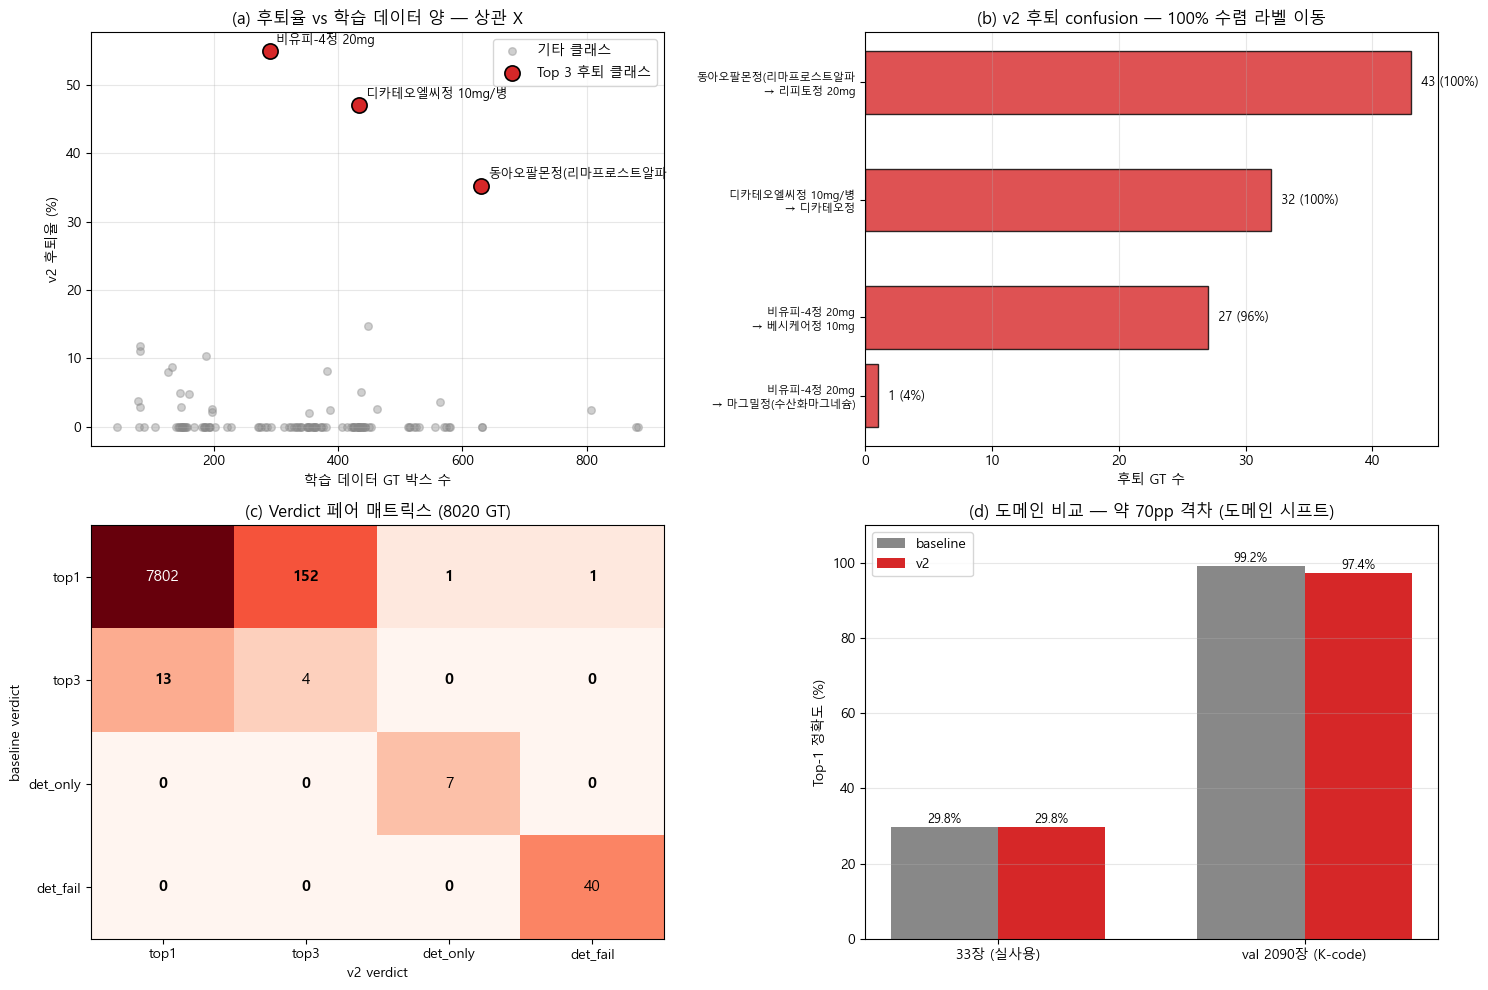


저장: D:\pill_detection\analysis\figures_generalization\08_phase_a23_summary.png


In [19]:
import matplotlib.pyplot as plt
import numpy as np

FIG_DIR = Path(r'D:\pill_detection\analysis\figures_generalization')
FIG_DIR.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# ───── (a) 후퇴율 vs 학습 데이터 양 ─────
ax = axes[0, 0]
all_classes = df_paired['gt_cat_name'].unique()
data_points = []
for cls in all_classes:
    cls_nfc = nfc(cls)
    train_n = class_counts_train.get(cls_nfc, 0)
    cls_total = (df_paired['gt_cat_name'] == cls).sum()
    cls_regr = ((df_paired['gt_cat_name'] == cls) &
                (df_paired['verdict_baseline'] == 'top1') &
                (df_paired['verdict_v2'] != 'top1')).sum()
    if cls_total > 0:
        data_points.append({
            'class': cls, 'train_n': train_n,
            'val_total': cls_total, 'regress_pct': cls_regr / cls_total * 100,
            'is_target': cls in TARGET_CLASSES,
        })

df_plot = pd.DataFrame(data_points)
ax.scatter(df_plot[~df_plot['is_target']]['train_n'],
           df_plot[~df_plot['is_target']]['regress_pct'],
           s=30, alpha=0.4, color='#888', label='기타 클래스')
ax.scatter(df_plot[df_plot['is_target']]['train_n'],
           df_plot[df_plot['is_target']]['regress_pct'],
           s=120, color='#d62728', edgecolor='black',
           linewidth=1.2, zorder=5, label='Top 3 후퇴 클래스')
for _, r in df_plot[df_plot['is_target']].iterrows():
    ax.annotate(r['class'][:15], (r['train_n'], r['regress_pct']),
                xytext=(5, 5), textcoords='offset points', fontsize=9)
ax.set_xlabel('학습 데이터 GT 박스 수')
ax.set_ylabel('v2 후퇴율 (%)')
ax.set_title('(a) 후퇴율 vs 학습 데이터 양 — 상관 X')
ax.grid(alpha=0.3)
ax.legend()

# ───── (b) v2 후퇴 confusion 분포 (Top 3 클래스 각각) ─────
ax = axes[0, 1]
y_pos = []
labels_y = []
y = 0
for cls_name in TARGET_CLASSES:
    cls_regr = df_regressed[df_regressed['gt_cat_name'] == cls_name]
    if len(cls_regr) == 0:
        continue
    confusion = cls_regr['top1_name_v2'].value_counts()
    for wrong_cls, cnt in confusion.head(2).items():
        ax.barh(y, cnt, color='#d62728', alpha=0.8, edgecolor='black')
        ax.text(cnt + 0.5, y, f' {cnt} ({cnt/len(cls_regr)*100:.0f}%)',
                va='center', fontsize=9)
        labels_y.append(f'{cls_name[:15]}\n→ {wrong_cls[:15]}')
        y_pos.append(y)
        y += 1
    y += 0.5

ax.set_yticks(y_pos)
ax.set_yticklabels(labels_y, fontsize=8)
ax.invert_yaxis()
ax.set_xlabel('후퇴 GT 수')
ax.set_title('(b) v2 후퇴 confusion — 100% 수렴 라벨 이동')
ax.grid(alpha=0.3, axis='x')

# ───── (c) verdict 페어 매트릭스 히트맵 ─────
ax = axes[1, 0]
verdict_order = ['top1', 'top3', 'det_only', 'det_fail']
mat = pair_matrix.values
im = ax.imshow(np.log10(mat + 1), cmap='Reds', aspect='auto')
for i in range(4):
    for j in range(4):
        val = mat[i, j]
        color = 'white' if val > 1000 else 'black'
        ax.text(j, i, f'{val}', ha='center', va='center',
                color=color, fontsize=11,
                fontweight='bold' if i != j else 'normal')
ax.set_xticks(range(4))
ax.set_yticks(range(4))
ax.set_xticklabels(verdict_order)
ax.set_yticklabels(verdict_order)
ax.set_xlabel('v2 verdict')
ax.set_ylabel('baseline verdict')
ax.set_title('(c) Verdict 페어 매트릭스 (8020 GT)')

# ───── (d) 도메인 비교 ─────
ax = axes[1, 1]
domains = ['33장 (실사용)', 'val 2090장 (K-code)']
top1_baseline = [29.8, 99.2]   # 33장 박제 + 이번 측정
top1_v2 = [29.8, 97.4]         # 33장 약 동일 + 이번 측정

x = np.arange(len(domains))
w = 0.35
ax.bar(x - w/2, top1_baseline, w, label='baseline', color='#888')
ax.bar(x + w/2, top1_v2, w, label='v2', color='#d62728')
for i, (b, v) in enumerate(zip(top1_baseline, top1_v2)):
    ax.text(i - w/2, b + 1, f'{b:.1f}%', ha='center', fontsize=9)
    ax.text(i + w/2, v + 1, f'{v:.1f}%', ha='center', fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(domains)
ax.set_ylabel('Top-1 정확도 (%)')
ax.set_title('(d) 도메인 비교 — 약 70pp 격차 (도메인 시프트)')
ax.set_ylim(0, 110)
ax.legend()
ax.grid(alpha=0.3, axis='y')

plt.tight_layout()
fig_path = FIG_DIR / '08_phase_a23_summary.png'
plt.savefig(fig_path, dpi=120, bbox_inches='tight')
plt.show()
print(f'\n저장: {fig_path}')

## Phase A-2/A-3 결과 종합

### 측정값 (val 2090장 / GT 8020개)

| 지표 | baseline (e15 best=e13) | v2 (e14 best=e14) | Δ |
|---|---|---|---|
| Top-1 | 99.2% (7956/8020) | 97.4% (7815/8020) | -1.8pp |
| Top-3 | 99.4% | 99.4% | 0.0pp |
| Detection rate | 99.5% | 99.5% | 0.0pp |
| 후퇴 GT | — | 154 | — |
| 회복 GT | — | 13 | — |

### 핵심 발견 4가지

**1. val 도메인 천장 효과**
- Top-1 양 모델 99%, Top-3 99.4% 동일
- 두 모델 진단 도구로 부적합 (mAP@50도 baseline 0.990 / v2 0.987로 0.3pp만 차이)

**2. 도메인 시프트 70pp 격차**
- 33장 (실사용 도메인): Top-1 약 29.8% (HANDOFF44 박제)
- val 2090 (K-code 흰배경): Top-1 99% 수준
- 모델이 K-code 흰배경에는 거의 완벽하게 fit, 실사용 도메인에는 작동 거의 안 함

**3. 라벨 이동 100% 수렴 패턴 (★ 결정적)**
- 후퇴 154 GT 중 67% (103개)가 3개 클래스에 집중
- 각 클래스의 v2 top1 오답이 단일 클래스로 100% 수렴:
  - 동아오팔몬정 → 리피토정 20mg (43건, 100%)
  - 디카테오엘씨정 10mg/병 → 디카테오정 (32건, 100%)
  - 비유피-4정 20mg → 베시케어정 10mg (27건, 96%)
- 무작위 혼동 아닌 양방향 정렬된 라벨 이동
- 33장에서 발견된 "에르도스테인 패밀리 라벨 이동" 패턴이 K-code val에서 재현 (엘스테인 → 알바스테인 5건)

**4. 학습 데이터 양과 후퇴 무관**
- 동아오팔몬 630개 학습 (118종 중 6위, 평균 1.9배) → 35% 후퇴
- 디카테오엘씨 434개 학습 (31위) → 47% 후퇴
- 비유피-4정 290개 학습 (73위) → 55% 후퇴
- 데이터 양 늘려도 라벨 이동 안 잡힘 = 진짜 원인은 클래스 자체의 시각 구분 가능성

### 처방 4 의사결정 시사

처방 4 (palm 30~50장 + 손가락 + 재사용 분산)는 합성 데이터 다양화. 그러나:
- 154 후퇴 중 103 (67%)가 라벨 이동 → 합성 처방으로 못 잡음
- 학습 양 늘려도 후퇴 → 데이터 양 처방 효과 약함
- 진짜 처방은 클래스 정의 차원:
  - (a) 시각 유사 쌍 학습 가중치 분리 (각인 영역 강조 loss)
  - (b) 각인 명시 학습 (K-code 각인 마스크)
  - (c) two-stage classifier 활용 (팀원 B님 CNN 분담)
  - (d) 동의어 처리 (에르도스테인 패밀리 통합)

### Figure 산출
- `figures_generalization/08_phase_a23_summary.png` — 4-panel (학습량 산점도 + confusion + verdict 매트릭스 + 도메인 비교)

### 다음 세션 (Phase A-4)
"모델이 각인을 보는가" 직접 검증.
동아오팔몬 vs 리피토정 (둘 다 원형/하양) ROI에서 grad-CAM으로 모델 시선 추출.
- 가설 1: 각인 안 봄 → 형태/색만 봄 → 라벨 이동 (가장 강한 가설)
- 가설 2: 각인 보긴 하지만 학습 시그널 부족